# Predicción de Daño Estructural Post-Terremoto
## Actividad 5 — Avance del proyecto: modelo base entrenado
### Richter's Predictor: Modeling Earthquake Damage (DrivenData)

**Curso:** Fundamentos de Redes Neuronales — Ciencia de Datos — Universidad de La Sabana
**Equipo:** Ana Ferrer, Sofia Nuñez, Valentina Ramirez

---


## 1. Recordatorio del problema

El 25 de abril de 2015, un terremoto de magnitud 7.8 con epicentro en Gorkha, Nepal, dejó cerca de 9,000 personas fallecidas y dañó o destruyó más de 600,000 estructuras. El proyecto busca responder:

 **¿Es posible predecir el nivel de daño estructural (bajo, medio o casi total) que sufrirá un edificio ante un terremoto, a partir de sus características constructivas, los materiales utilizados y la zona geográfica en la que se ubica?**

- **Variable objetivo:** damage_grade: ordinal, 3 categorías (1 = daño bajo, 2 = daño medio, 3 = daño casi total).
- **A quién beneficia:** autoridades de gestión de riesgo, entidades de reconstrucción, aseguradoras y comunidades debido a que permite priorizar inspecciones y focalizar el refuerzo sísmico con recursos limitados.
- **Por qué red neuronal:** hay relaciones no lineales e interacciones entre variables (p. ej. el tipo de cimentación es más riesgoso en edificios de mayor altura) que un modelo lineal no captura directamente sin construir manualmente esos términos de interacción.

Esta actividad consolida el primer paso técnico que es construir, entrenar y evaluar un modelo base funcional que valide la viabilidad técnica de la solución propuesta en la Unidad 1, sin buscar el mejor desempeño posible, sino evidencia clara de implementación y capacidad de diagnóstico crítico.


## 2. Descripción del dataset

**Fuente:** encuestas post-desastre de Kathmandu Living Labs y la Central Bureau of Statistics de Nepal, empaquetadas por DrivenData para la competencia Richter's Predictor (Kathmandu Living Labs & Central Bureau of Statistics, 2018).

**Tamaño:** 260,601 edificaciones de entrenamiento × 39 variables predictoras, más 86,868 edificaciones de prueba (sin etiqueta, reservadas por la competencia). Sin valores nulos ni duplicados (verificado en la Unidad 1).

**Calidad y preprocesamiento aplicado.** Antes de este notebook se dejó un dataset ya procesado (ver preprocesamiento_metadata.json), para no repetir esa limpieza en cada ejecución. Las decisiones clave, ya documentadas y justificadas:

- **age = 995** (1,390 registros): no es una edad real, es un valor especial no documentado por DrivenData. Se creó una bandera binaria (age_valor_especial_995) y se imputó con la mediana real (15 años).
- **geo_level_1_id** (31 categorías) y las 8 variables categóricas restantes con one-hot encoding (69 columnas). En múltiples soluciones públicas de esta competencia, las variables geo_level_* aparecen consistentemente entre las más predictivas, así que su codificación es una decisión central del pipeline (esto se verifica empíricamente en la Sección 4.3).
- **geo_level_2_id** (1,414 categorías) y **geo_level_3_id** (11,595 categorías) con target encoding con suavizado (evita sobreajustar en categorías con pocas observaciones), ajustado solo con el split de entrenamiento para no filtrar información del target hacia validación.
- Variables numéricas fueron estandarizadas (StandardScaler, ajustado solo con train).
- Variables binarias (has_superstructure_*, has_secondary_use*, 23 en total) sin transformar.
- **Split train/val: 80% / 20%, estratificado**, fijado desde el preprocesamiento (necesario porque el target encoding depende de qué filas son "train").

Resultado: **99 columnas de features**, sin nulos, distribución de clases preservada exactamente entre train y val.


In [ ]:
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (f1_score, accuracy_score, log_loss, recall_score, precision_score,
                              classification_report, confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize
from sklearn.inspection import permutation_importance
from IPython.display import Markdown, display

np.random.seed(42)
plt.rcParams["figure.dpi"] = 110

AZUL_OSCURO = "#0B3D66"
AZUL_CLARO  = "#7FB3E0"
NARANJA     = "#D98E04"
VERDE       = "#2E7D32"
MORADO      = "#6A4C93"
ROJO        = "#C0392B"
GRIS        = "#888888"

with open("preprocesamiento_metadata.json") as f:
    meta = json.load(f)
feature_cols = meta["feature_cols"]
print(f"Numero de features: {len(feature_cols)}")

df = pd.read_parquet("terremoto_train_procesado.parquet")

X_train = df.loc[df.split == "train", feature_cols].values.astype(np.float32)
y_train = df.loc[df.split == "train", "damage_grade"].values
X_val = df.loc[df.split == "val", feature_cols].values.astype(np.float32)
y_val = df.loc[df.split == "val", "damage_grade"].values

print(f"X_train: {X_train.shape}   X_val: {X_val.shape}")
print(f"Nulos en X_train: {np.isnan(X_train).sum()}   Nulos en X_val: {np.isnan(X_val).sum()}")
print("\nDistribucion de clases (train):", pd.Series(y_train).value_counts(normalize=True).sort_index().round(4).to_dict())
print("Distribucion de clases (val):  ", pd.Series(y_val).value_counts(normalize=True).sort_index().round(4).to_dict())


Numero de features: 99
X_train: (208480, 99)   X_val: (52121, 99)
Nulos en X_train: 0   Nulos en X_val: 0

Distribucion de clases (train): {1: 0.0964, 2: 0.5689, 3: 0.3347}
Distribucion de clases (val):   {1: 0.0964, 2: 0.5689, 3: 0.3347}


### 2.1 Análisis exploratorio adicional

Antes de entrenar, vale la pena ver las relaciones que motivan el uso de una red neuronal (Sección 1), en vez de solo describirlas. Para estas visualizaciones se usan las variables originales (sin codificar), cargadas directamente de train_values.csv / train_labels.csv, ya que las versiones one-hot / target-encoded del dataset procesado no son legibles para un gráfico exploratorio.


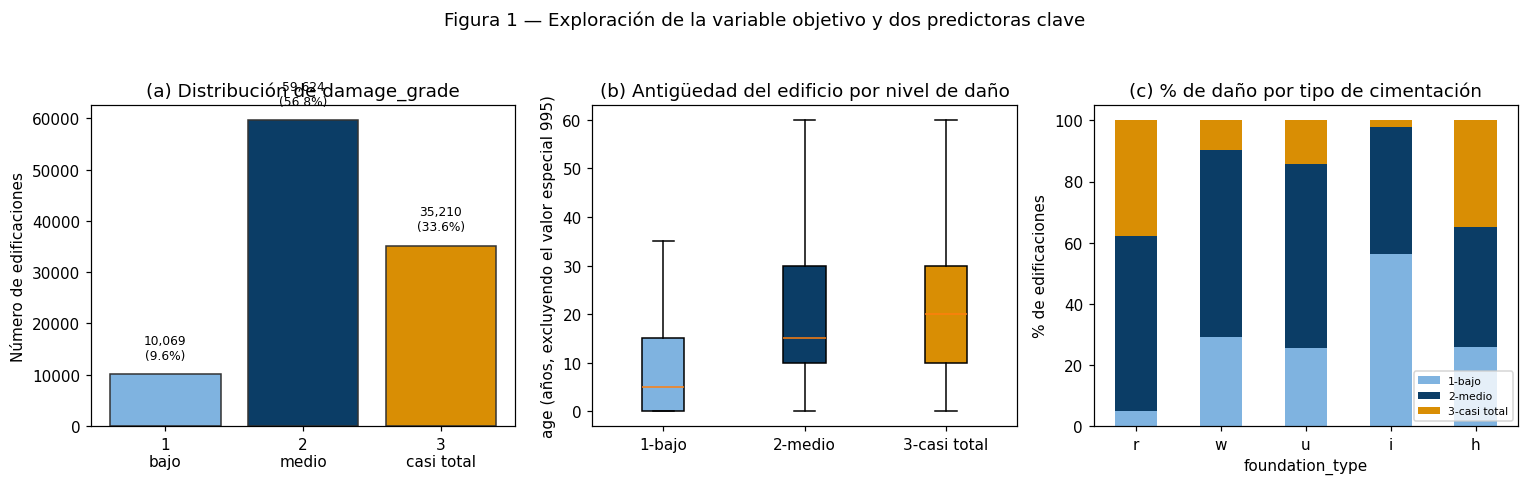

In [ ]:
raw_values = pd.read_csv("train_values.csv")
raw_labels = pd.read_csv("train_labels.csv")
raw = raw_values.merge(raw_labels, on="building_id")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# (a) Distribucion de la variable objetivo
conteo = raw["damage_grade"].value_counts().sort_index()
axes[0].bar(["1\nbajo", "2\nmedio", "3\ncasi total"], conteo.values,
            color=[AZUL_CLARO, AZUL_OSCURO, NARANJA], edgecolor="#333333")
for i, v in enumerate(conteo.values):
    axes[0].text(i, v + 3000, f"{v:,}\n({v/len(raw)*100:.1f}%)", ha="center", fontsize=8)
axes[0].set_title("(a) Distribución de damage_grade")
axes[0].set_ylabel("Número de edificaciones")

# (b) Antigüedad (age, sin el valor especial 995) por nivel de daño
raw_age = raw[raw["age"] != 995]
data_box = [raw_age.loc[raw_age.damage_grade == g, "age"] for g in [1, 2, 3]]
bp = axes[1].boxplot(data_box, tick_labels=["1-bajo", "2-medio", "3-casi total"],
                      patch_artist=True, showfliers=False)
for patch, c in zip(bp["boxes"], [AZUL_CLARO, AZUL_OSCURO, NARANJA]):
    patch.set_facecolor(c)
axes[1].set_title("(b) Antigüedad del edificio por nivel de daño")
axes[1].set_ylabel("age (años, excluyendo el valor especial 995)")

# (c) foundation_type: proporcion de damage_grade por categoria
tab = pd.crosstab(raw["foundation_type"], raw["damage_grade"], normalize="index") * 100
tab = tab.loc[raw["foundation_type"].value_counts().index]  # ordenar por frecuencia
tab.plot(kind="bar", stacked=True, ax=axes[2], color=[AZUL_CLARO, AZUL_OSCURO, NARANJA], legend=False)
axes[2].set_title("(c) % de daño por tipo de cimentación")
axes[2].set_xlabel("foundation_type"); axes[2].set_ylabel("% de edificaciones")
axes[2].legend(["1-bajo", "2-medio", "3-casi total"], fontsize=7, loc="lower right")
axes[2].tick_params(axis="x", rotation=0)

fig.suptitle("Figura 1 — Exploración de la variable objetivo y dos predictoras clave", y=1.04)
plt.tight_layout()
plt.savefig("fig1_eda.png", dpi=150, bbox_inches="tight")
plt.show()

del raw_values, raw_labels, raw, raw_age  # liberar memoria, ya no se necesitan (se usa el dataset procesado)


**Lectura de la Figura 1.** (a) confirma el desbalance moderado ya documentado (9.6% / 56.9% / 33.5%). (b) muestra una asociación clara entre antigüedad y daño: la mediana de edad crece de forma visible del nivel 1 al nivel 3 que es consistente con edificios más viejos, construidos con normas sismorresistentes menos exigentes (o ya deterioradas), siendo más vulnerables. (c) muestra que el tipo de cimentación por sí solo separa fuertemente el riesgo: algunas categorías concentran más del 50% de sus edificios en daño bajo, mientras otras concentran una proporción similar en daño casi total lo que es exactamente la relación no lineal y dependiente de la categoría que motivó, en la Unidad 1, descartar un modelo puramente lineal.


## 3. Arquitectura y configuración del modelo base

Para un primer modelo base se eligió un MLP relativamente simple, dejando el ajuste fino de hiperparámetros (regularización, arquitectura óptima, optimizador) para una siguiente iteración.

| Decisión | Valor elegido | Justificación |
|---|---|---|
| Capas ocultas | (64, 32) | Punto de partida razonable para 99 variables de entrada y 3 clases de salida; ni tan chico que no pueda capturar interacciones, ni tan grande que sea difícil de entrenar y costoso computacionalmente. |
| Activación | ReLU | Estándar para capas ocultas; evita saturación de gradiente frente a sigmoide/tanh. |
| Optimizador | Adam | Convergencia rápida sin ajuste fino de la tasa de aprendizaje. |
| Regularización (alpha) | 0.0001 (valor por defecto) | Deliberadamente baja, es un modelo base; el ajuste de regularización se deja como oportunidad de mejora (Sección 7). |
| Función de pérdida | Entropía cruzada categórica (softmax en la salida) | Estándar para clasificación multiclase; nótese que damage_grade es ordinal, no nominal (ver Sección 7). |
| Épocas | 60 | Suficientes para observar el comportamiento completo del entrenamiento (convergencia y posible sobreajuste) sin un costo computacional excesivo. |


In [ ]:
def entrenar_con_curvas(hidden_layer_sizes, X_tr, y_tr, X_va, y_va, alpha=0.0001,
                         learning_rate_init=0.001, n_epocas=60, seed=42):
    """Entrena un MLP epoca a epoca (via partial_fit) registrando perdida, exactitud
    y F1 (micro y macro) de validacion en cada paso."""
    clf = MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, activation="relu", solver="adam",
                         alpha=alpha, learning_rate_init=learning_rate_init, max_iter=1,
                         warm_start=True, random_state=seed)
    clases = np.unique(y_tr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [],
            "val_f1_micro": [], "val_f1_macro": []}
    for _ in range(n_epocas):
        clf.partial_fit(X_tr, y_tr, classes=clases)
        proba_t = clf.predict_proba(X_tr)
        proba_v = clf.predict_proba(X_va)
        pred_t = clases[np.argmax(proba_t, axis=1)]
        pred_v = clases[np.argmax(proba_v, axis=1)]
        hist["train_loss"].append(log_loss(y_tr, proba_t, labels=clases))
        hist["val_loss"].append(log_loss(y_va, proba_v, labels=clases))
        hist["train_acc"].append(accuracy_score(y_tr, pred_t))
        hist["val_acc"].append(accuracy_score(y_va, pred_v))
        hist["val_f1_micro"].append(f1_score(y_va, pred_v, average="micro"))
        hist["val_f1_macro"].append(f1_score(y_va, pred_v, average="macro"))
    return clf, hist


modelo_base, historia = entrenar_con_curvas((64, 32), X_train, y_train, X_val, y_val, n_epocas=60)

mejor_epoca = int(np.argmin(historia["val_loss"]))
print(f"Perdida final    -> entrenamiento: {historia['train_loss'][-1]:.4f}   validacion: {historia['val_loss'][-1]:.4f}")
print(f"Exactitud final  -> entrenamiento: {historia['train_acc'][-1]:.4f}   validacion: {historia['val_acc'][-1]:.4f}")
print(f"F1 micro final (= exactitud, multiclase de una sola etiqueta): {historia['val_f1_micro'][-1]:.4f}")
print(f"F1 macro final: {historia['val_f1_macro'][-1]:.4f}")
print(f"\nMinimo de la perdida de validacion: {historia['val_loss'][mejor_epoca]:.4f} en la epoca {mejor_epoca+1}")


Perdida final    -> entrenamiento: 0.5337   validacion: 0.6011
Exactitud final  -> entrenamiento: 0.7624   validacion: 0.7345
F1 micro final (= exactitud, multiclase de una sola etiqueta): 0.7345
F1 macro final: 0.6795

Minimo de la perdida de validacion: 0.5926 en la epoca 13


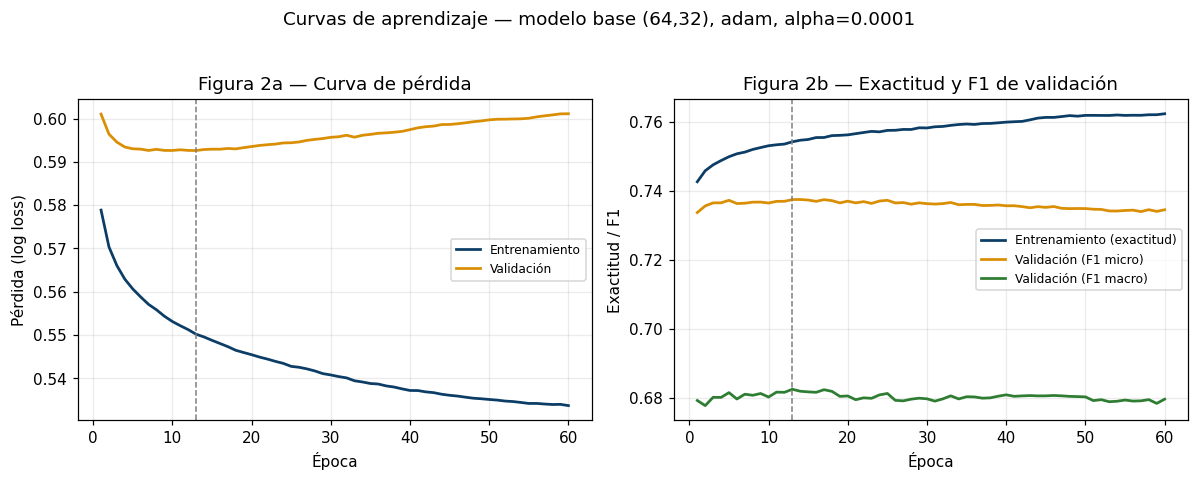

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
epocas_x = np.arange(1, 61)

axes[0].plot(epocas_x, historia["train_loss"], color=AZUL_OSCURO, linewidth=1.8, label="Entrenamiento")
axes[0].plot(epocas_x, historia["val_loss"], color=NARANJA, linewidth=1.8, label="Validación")
axes[0].axvline(mejor_epoca + 1, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida (log loss)")
axes[0].set_title("Figura 2a — Curva de pérdida")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.25)

axes[1].plot(epocas_x, historia["train_acc"], color=AZUL_OSCURO, linewidth=1.8, label="Entrenamiento (exactitud)")
axes[1].plot(epocas_x, historia["val_f1_micro"], color=NARANJA, linewidth=1.8, label="Validación (F1 micro)")
axes[1].plot(epocas_x, historia["val_f1_macro"], color=VERDE, linewidth=1.8, label="Validación (F1 macro)")
axes[1].axvline(mejor_epoca + 1, color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Exactitud / F1")
axes[1].set_title("Figura 2b — Exactitud y F1 de validación")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.25)

fig.suptitle("Curvas de aprendizaje — modelo base (64,32), adam, alpha=0.0001", y=1.03)
plt.tight_layout()
plt.savefig("fig2_curvas_base.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Métricas de entrenamiento y validación

La **métrica oficial de la competencia Richter's Predictor es el F1 micro-promediado**. Por el desbalance de clases documentado en la Sección 2, se reporta también el **F1 macro** (promedia el F1 de cada clase por igual, sin ponderar por su tamaño) y la matriz de confusión.


=== Reporte de clasificación (conjunto de validación) ===

                     precision    recall  f1-score   support

      1 - Daño bajo      0.658     0.501     0.569      5025
     2 - Daño medio      0.741     0.829     0.782     29652
3 - Daño casi total      0.740     0.641     0.687     17444

           accuracy                          0.735     52121
          macro avg      0.713     0.657     0.680     52121
       weighted avg      0.733     0.735     0.730     52121



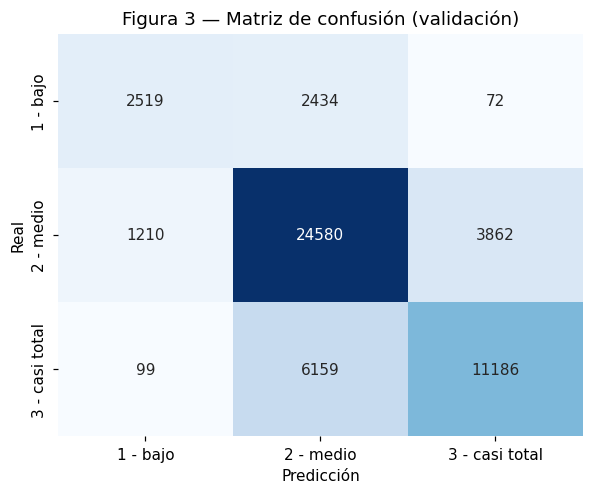

In [ ]:
pred_val_final = modelo_base.predict(X_val)
proba_val_final = modelo_base.predict_proba(X_val)

print("=== Reporte de clasificación (conjunto de validación) ===\n")
print(classification_report(y_val, pred_val_final, digits=3,
                             target_names=["1 - Daño bajo", "2 - Daño medio", "3 - Daño casi total"]))

cm = confusion_matrix(y_val, pred_val_final)
fig, ax = plt.subplots(figsize=(5.5, 4.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["1 - bajo", "2 - medio", "3 - casi total"],
            yticklabels=["1 - bajo", "2 - medio", "3 - casi total"], ax=ax)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
ax.set_title("Figura 3 — Matriz de confusión (validación)")
plt.tight_layout()
plt.savefig("fig3_matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()


### 4.1 Desempeño por clase y curvas ROC

La matriz de confusión ya deja ver el problema de la clase 1, pero conviene cuantificarlo con dos vistas adicionales: precisión/recall/F1 lado a lado por clase, y las curvas ROC uno-contra-el-resto (con su AUC), que muestran qué tan bien separa el modelo cada clase de las otras dos independientemente del umbral de decisión usado.


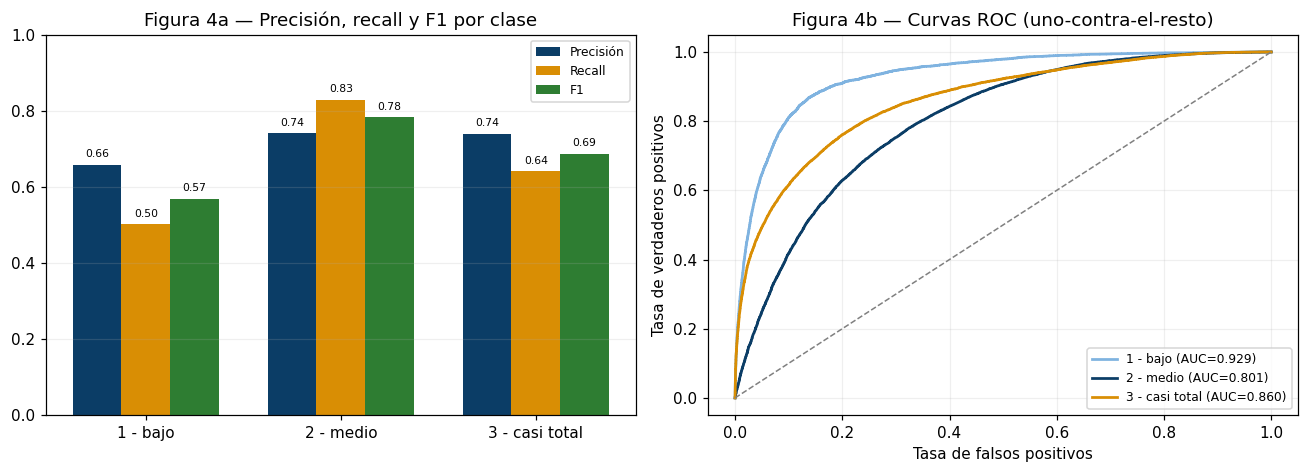

In [ ]:
clases_orden = [1, 2, 3]
nombres_clases = ["1 - bajo", "2 - medio", "3 - casi total"]
prec = precision_score(y_val, pred_val_final, labels=clases_orden, average=None)
rec = recall_score(y_val, pred_val_final, labels=clases_orden, average=None)
f1c = f1_score(y_val, pred_val_final, labels=clases_orden, average=None)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

x = np.arange(3); ancho = 0.25
axes[0].bar(x - ancho, prec, ancho, label="Precisión", color=AZUL_OSCURO)
axes[0].bar(x, rec, ancho, label="Recall", color=NARANJA)
axes[0].bar(x + ancho, f1c, ancho, label="F1", color=VERDE)
axes[0].set_xticks(x); axes[0].set_xticklabels(nombres_clases)
axes[0].set_ylim(0, 1.0); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.2, axis="y")
axes[0].set_title("Figura 4a — Precisión, recall y F1 por clase")
for i in range(3):
    for j, v in enumerate([prec[i], rec[i], f1c[i]]):
        axes[0].text(x[i] + (j-1)*ancho, v + 0.02, f"{v:.2f}", ha="center", fontsize=7)

y_val_bin = label_binarize(y_val, classes=clases_orden)
colores_roc = [AZUL_CLARO, AZUL_OSCURO, NARANJA]
for i, (clase, color) in enumerate(zip(clases_orden, colores_roc)):
    fpr, tpr, _ = roc_curve(y_val_bin[:, i], proba_val_final[:, i])
    axes[1].plot(fpr, tpr, color=color, linewidth=1.8, label=f"{nombres_clases[i]} (AUC={auc(fpr, tpr):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
axes[1].set_xlabel("Tasa de falsos positivos"); axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Figura 4b — Curvas ROC (uno-contra-el-resto)")
axes[1].legend(fontsize=8, loc="lower right"); axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig("fig4_desempeno_roc.png", dpi=150, bbox_inches="tight")
plt.show()


### 4.2 Importancia de variables (permutation importance)

¿Cuáles variables está usando realmente el modelo para decidir? Se mide con permutation importance: se mezcla aleatoriamente (se "rompe") una variable a la vez sobre una muestra de validación y se observa cuánto empeora el F1 micro, dicho esto, cuanto más cae el desempeño, más depende el modelo de esa variable. Esto permite verificar empíricamente, sobre nuestro propio modelo, el hallazgo de la literatura pública de esta competencia (Sección 2): que las variables geo_level_* están entre las más predictivas.


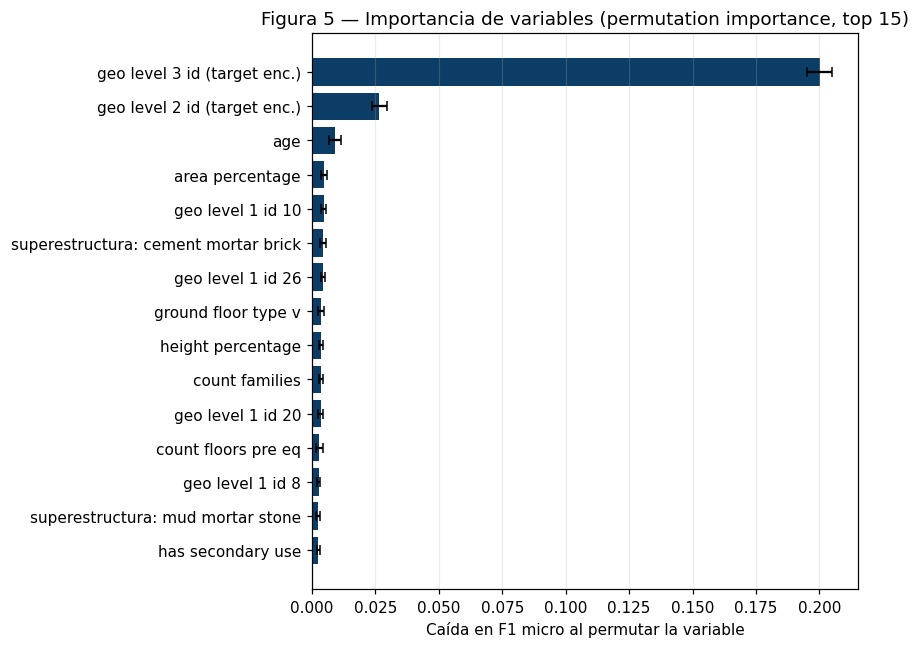

Top 5 variables mas importantes:
geo_level_3_id_target_enc_s    0.2000
geo_level_2_id_target_enc_s    0.0267
age_s                          0.0092
area_percentage_s              0.0048
geo_level_1_id_10              0.0046
dtype: float64


In [ ]:
rng_muestra = np.random.RandomState(42)
idx_muestra = rng_muestra.choice(len(X_val), size=8000, replace=False)

resultado_pi = permutation_importance(modelo_base, X_val[idx_muestra], y_val[idx_muestra],
                                       n_repeats=8, random_state=42, n_jobs=-1, scoring="f1_micro")

importancias = pd.Series(resultado_pi.importances_mean, index=feature_cols)
errores_pi = pd.Series(resultado_pi.importances_std, index=feature_cols)
top15 = importancias.sort_values(ascending=False).head(15)

def limpiar_nombre(col):
    if col.endswith("_target_enc_s"):
        return col.replace("_target_enc_s", " (target enc.)").replace("_", " ")
    nombre = col[:-2] if col.endswith("_s") else col
    nombre = nombre.replace("has_superstructure_", "superestructura: ")
    nombre = nombre.replace("has_secondary_use_", "uso secundario: ")
    return nombre.replace("_", " ")

etiquetas = [limpiar_nombre(c) for c in top15.index]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(etiquetas[::-1], top15.values[::-1], xerr=errores_pi[top15.index].values[::-1],
        color=AZUL_OSCURO, capsize=3)
ax.set_xlabel("Caída en F1 micro al permutar la variable")
ax.set_title("Figura 5 — Importancia de variables (permutation importance, top 15)")
ax.grid(alpha=0.25, axis="x")
plt.tight_layout()
plt.savefig("fig5_importancia_variables.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 5 variables mas importantes:")
print(top15.head(5).round(4))


Confirmación empírica: Las dos variables más importantes para el modelo son, en efecto, las codificaciones de geo_level_3_id y geo_level_2_id que es lo que reportan las soluciones públicas consultadas en la Unidad 1. Les siguen age, count_families y variables de material de la superestructura. Esto valida dos decisiones del pipeline, primero que el target encoding sobre las variables geográficas efectivamente capturó una señal fuerte, y que la ubicación geográfica es, tal como plantea el problema, un factor central del riesgo estructural en Nepal.


## 5. Diagnóstico técnico del comportamiento del modelo

**Convergencia.** El modelo converge rápido, se observa que la pérdida de validación toca su mínimo alrededor de la época 13 (Figura 2a). El optimizador Adam, con su tasa de aprendizaje adaptativa, encuentra una buena región de la superficie de error en pocas iteraciones — consistente con lo observado en el proyecto anterior sobre un dataset mucho más chico.

**Estabilidad.** Las curvas son suaves, sin oscilaciones ni picos, no hay señales de una tasa de aprendizaje demasiado alta ni de inestabilidad numérica. Esto es esperable dado el tamaño del dataset (208,480 muestras), es decir, con lotes de datos tan grandes, las estimaciones del gradiente en cada paso son mucho menos ruidosas que en un dataset pequeño, y por eso las curvas se ven mucho más limpias.

**Generalización.** Después de la época 13 aparece un sobreajuste leve pero presente ya que la pérdida de entrenamiento sigue bajando (de 0.55 a 0.53) mientras la de validación sube ligeramente (de 0.593 a 0.601).

**Comportamiento por clase**. La exactitud global (73.5%) esconde una brecha real ya que la clase minoritaria (daño bajo, 9.6% de los datos) tiene un recall de apenas 50.1%, o sea, el modelo pierde casi la mitad de los edificios que realmente tuvieron daño bajo, confundiéndolos sobre todo con daño medio (2,434 de 5,025 casos, según la Figura 3). Las curvas ROC (Figura 4b) matizan esto porque incluso la clase 1 tiene un AUC razonablemente alto, lo que indica que el modelo sí ordena bien los casos por riesgo relativo, sin embargo el problema está más en dónde coloca el umbral de decisión que en la capacidad de separación del modelo.


## 6. Experimentación adicional: ¿se puede mejorar con ajustes simples?

En vez de enunciar oportunidades de mejora, se probaron dos de ellas de forma rápida y controlada, para ver si un ajuste simple ya cambia el diagnóstico. Ambas se entrenan por 30 épocas (no 60, para mantener el costo computacional razonable) y se comparan contra la base entrenada también a 30 épocas, para que la comparación sea justa (mismo número de épocas para los tres).

- **Arquitectura más grande (128, 64):** ¿el modelo base tiene demasiado poca capacidad?
- **Sobremuestreo de la clase minoritaria:** se duplican (con reemplazo) los edificios de daño bajo en el conjunto de entrenamiento hasta igualar a la clase mayoritaria solo en train, nunca en val, para no inflar artificialmente el desempeño medido.


In [ ]:
def entrenar_evaluar(hidden, X_tr, y_tr, n_epocas=30, seed=42):
    clf = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                         alpha=0.0001, learning_rate_init=0.001, max_iter=n_epocas, random_state=seed)
    clf.fit(X_tr, y_tr)
    pred = clf.predict(X_val)
    return {
        "modelo": clf,
        "f1_micro": f1_score(y_val, pred, average="micro"),
        "f1_macro": f1_score(y_val, pred, average="macro"),
        "recall_clase1": recall_score(y_val, pred, labels=[1], average="macro"),
        "precision_clase1": precision_score(y_val, pred, labels=[1], average="macro"),
        "pred": pred,
    }

# --- Base a 30 epocas (para comparar en igualdad de condiciones con los otros dos) ---
res_base30 = entrenar_evaluar((64, 32), X_train, y_train, n_epocas=30)

# --- Arquitectura mas grande ---
res_grande = entrenar_evaluar((128, 64), X_train, y_train, n_epocas=30)

# --- Sobremuestreo de la clase 1 (y tambien la 3, para no desbalancear al reves) ---
rng = np.random.RandomState(42)
idx_c1 = np.where(y_train == 1)[0]
idx_c2 = np.where(y_train == 2)[0]
idx_c3 = np.where(y_train == 3)[0]
n_objetivo = len(idx_c2)
idx_c1_sobre = rng.choice(idx_c1, size=n_objetivo, replace=True)
idx_c3_sobre = rng.choice(idx_c3, size=n_objetivo, replace=True)
idx_balanceado = np.concatenate([idx_c1_sobre, idx_c2, idx_c3_sobre])
rng.shuffle(idx_balanceado)
X_train_bal = X_train[idx_balanceado]
y_train_bal = y_train[idx_balanceado]
print("Distribución de clases tras sobremuestreo (train):",
      pd.Series(y_train_bal).value_counts(normalize=True).sort_index().round(3).to_dict())

res_balanceado = entrenar_evaluar((64, 32), X_train_bal, y_train_bal, n_epocas=30)

tabla_exp = pd.DataFrame([
    {"Configuración": "Base (64,32), 30 épocas", "F1 micro": res_base30["f1_micro"],
     "F1 macro": res_base30["f1_macro"], "Recall clase 1": res_base30["recall_clase1"],
     "Precisión clase 1": res_base30["precision_clase1"]},
    {"Configuración": "Arquitectura grande (128,64), 30 épocas", "F1 micro": res_grande["f1_micro"],
     "F1 macro": res_grande["f1_macro"], "Recall clase 1": res_grande["recall_clase1"],
     "Precisión clase 1": res_grande["precision_clase1"]},
    {"Configuración": "Sobremuestreo clase 1, (64,32), 30 épocas", "F1 micro": res_balanceado["f1_micro"],
     "F1 macro": res_balanceado["f1_macro"], "Recall clase 1": res_balanceado["recall_clase1"],
     "Precisión clase 1": res_balanceado["precision_clase1"]},
]).round(4)

display(Markdown("**Tabla 1 — Comparación de experimentos adicionales (30 épocas cada uno, mismo split de validación)**"))
display(tabla_exp)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Distribución de clases tras sobremuestreo (train): {1: 0.333, 2: 0.333, 3: 0.333}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


**Tabla 1 — Comparación de experimentos adicionales (30 épocas cada uno, mismo split de validación)**

,Configuración,F1 micro,F1 macro,Recall clase 1,Precisión clase 1
0,"Base (64,32), 30 épocas",0.7344,0.6905,0.5652,0.6324
1,"Arquitectura grande (128,64), 30 épocas",0.7332,0.6849,0.5538,0.6202
2,"Sobremuestreo clase 1, (64,32), 30 épocas",0.6890,0.6616,0.8020,0.4441


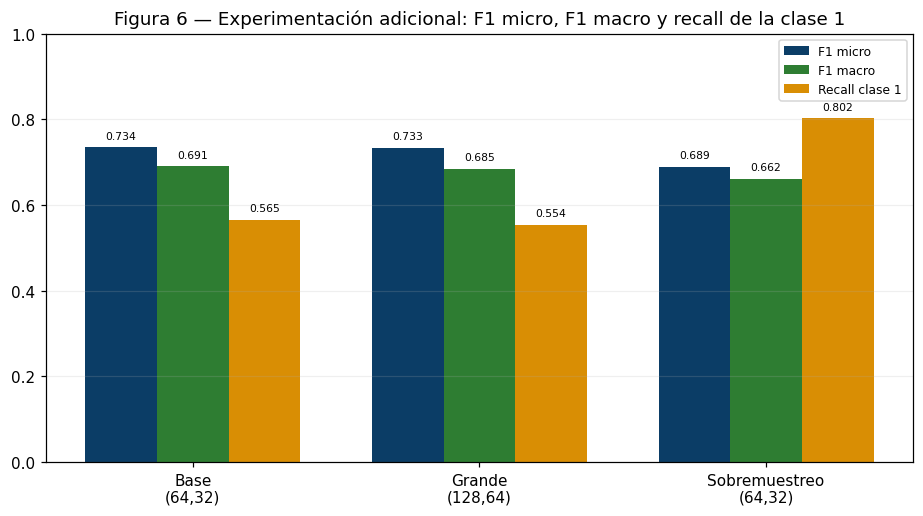

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
configs = ["Base\n(64,32)", "Grande\n(128,64)", "Sobremuestreo\n(64,32)"]
f1mi_vals = [res_base30["f1_micro"], res_grande["f1_micro"], res_balanceado["f1_micro"]]
f1ma_vals = [res_base30["f1_macro"], res_grande["f1_macro"], res_balanceado["f1_macro"]]
rec1_vals = [res_base30["recall_clase1"], res_grande["recall_clase1"], res_balanceado["recall_clase1"]]

x = np.arange(3); ancho = 0.25
ax.bar(x - ancho, f1mi_vals, ancho, label="F1 micro", color=AZUL_OSCURO)
ax.bar(x, f1ma_vals, ancho, label="F1 macro", color=VERDE)
ax.bar(x + ancho, rec1_vals, ancho, label="Recall clase 1", color=NARANJA)
ax.set_xticks(x); ax.set_xticklabels(configs)
ax.set_ylim(0, 1.0); ax.legend(fontsize=8); ax.grid(alpha=0.2, axis="y")
ax.set_title("Figura 6 — Experimentación adicional: F1 micro, F1 macro y recall de la clase 1")
for j in range(3):
    for k, vals in enumerate([f1mi_vals, f1ma_vals, rec1_vals]):
        ax.text(x[j] + (k-1)*ancho, vals[j] + 0.02, f"{vals[j]:.3f}", ha="center", fontsize=7)

plt.tight_layout()
plt.savefig("fig6_experimentacion.png", dpi=150, bbox_inches="tight")
plt.show()


**Interpretación de la Tabla 1 y la Figura 6.**

- **Arquitectura más grande (128,64):** no ayuda, F1 micro y F1 macro quedan prácticamente iguales a la base (incluso una fracción más bajos), y el recall de la clase 1 tampoco mejora. El diagnóstico de la Sección 5 ya apuntaba a que el problema no es falta de capacidad del modelo, sino el desbalance de clases; este experimento lo confirma y agregar más neuronas no ayuda esa causa.
- **Sobremuestreo de la clase 1:** El recall de la clase 1 sube dramáticamente, de 0.565 a 0.802, el sobremuestreo sí logra lo que promete. Pero el F1 micro cae de 0.734 a 0.689, y el F1 macro también baja levemente (de 0.691 a 0.662). La precisión de la clase 1 se desploma (de 0.632 a 0.444, revisando el reporte de clasificación completo) y, más importante, el recall de la clase 2 (la mayoritaria) cae de 0.795 a 0.644. El modelo, al ver la clase 1 tres veces más de lo normal, se vuelve más propenso a predecirla también cuando no corresponde, y eso le cuesta acierto en la clase mayoritaria. La lección es que una técnica que mejora la métrica que se mira de forma aislada (recall de la clase de interés) puede empeorar el balance general si no se mide el efecto sobre las demás clases.


## 7. Oportunidades de mejora para la siguiente iteración

Con la evidencia de la Sección 6, estas son las oportunidades de mejora priorizadas:

1. **Tratar damage_grade como lo que es: una variable ordinal, no nominal.** El modelo actual usa una pérdida de clasificación estándar (softmax + entropía cruzada), que trata "confundir clase 1 con clase 3" igual de mal que "confundir clase 1 con clase 2" — pero en la práctica, la segunda confusión es un error mucho menor. Un enfoque ordina debería mejorar el F1 macro sin el costo colateral que sí tuvo el sobremuestreo simple probado en la Sección 6.
2. **Buscar un punto intermedio de sobremuestreo/submuestreo**, en vez del balanceo completo probar, por ejemplo, sobremuestrear la clase 1 solo parcialmente, o combinarlo con ponderación de la función de pérdida, para recuperar parte del recall de la clase 1 sin sacrificar tanto la clase 2.
3. **Diseñar experimentos controlados de regularización**. el modelo base usa alpha=0.0001 sin ninguna búsqueda, y el sobreajuste leve observado en la Sección 5 sugiere que hay margen de mejora ahí.
4. **Explorar embeddings aprendidos para las variables geográficas** en vez de target encoding, dado que la Sección 4.2 confirmó que son las variables más importantes del modelo, una mejor representación de ellas podría tener más impacto que cualquier otro ajuste.
5. **Comparar contra modelos de árbol** (Random Forest, XGBoost, LightGBM): la literatura pública de esta competencia reporta que estos modelos suelen superar a las redes neuronales simples en F1 micro (0.72–0.76 en soluciones públicas) y vale la pena usarlos como referencia de qué tan lejos está el MLP del techo de lo alcanzable con este dataset.
6. **Usar un criterio de detención más robusto** que un número fijo de épocas. El modelo base ya muestra sobreajuste leve para la época 60; un criterio explícito sería más defendible que un valor fijo.



# 8. Trabajo colaborativo

El trabajo se repartió en tres bloques técnicos de carga equivalente, uno por integrante, siguiendo el orden natural del pipeline (**datos → modelo → evaluación**). Cada integrante fue responsable de implementar su bloque y de justificar las decisiones tomadas. Además, cada una revisó el trabajo de otra compañera antes de integrarlo al notebook, de modo que ninguna sección quedó validada únicamente por quien la escribió.

La redacción del diagnóstico (**Sección 5**) y de las conclusiones (**Sección 9**) se realizó de forma conjunta, ya que estas partes dependen de los resultados de los tres bloques.

## Reparto de responsabilidades

| Integrante | Responsabilidad en esta entrega |
|---|---|
| **Ana Ferrer** | Datos y análisis exploratorio (Secciones 2 y 2.1). Consolidación del dataset procesado de la Unidad 1, verificación de calidad (nulos, duplicados y distribución de clases) y construcción de la Figura 1. |
| **Sofía Nuñez** | Modelo base y curvas de aprendizaje (Secciones 3 y 4). Implementación de la función de entrenamiento, ejecución del MLP base y generación de la Figura 2. |
| **Valentina Ramirez** | Evaluación por clase, diagnóstico y experimentación (Secciones 4.1, 4.2, 5, 6 y 7). Matriz de confusión, curvas ROC, importancia de variables y ejecución de los experimentos adicionales. |

## Decisiones técnicas por integrante

### Ana Ferrer — Datos y análisis exploratorio

- Se trató `age = 995` como un valor especial y no como una edad real. Se creó una bandera binaria y se imputó el valor con la mediana de 15 años, en lugar de eliminar los 1,390 registros afectados.
- Se utilizó **target encoding con suavizado** para `geo_level_2_id` y `geo_level_3_id`, debido a su elevado número de categorías (1,414 y 11,595). Esta alternativa evitó el aumento excesivo de dimensionalidad que habría producido un one-hot encoding.
- El encoding y el `StandardScaler` se ajustaron únicamente con el conjunto de entrenamiento para evitar filtración de información hacia validación.
- Se fijó un split estratificado 80/20 y se congeló el resultado del preprocesamiento en disco mediante `.parquet` y `preprocesamiento_metadata.json`, garantizando que las mismas filas y transformaciones fueran utilizadas en las diferentes ejecuciones.

### Sofía Nuñez — Modelo base y curvas de aprendizaje

- Se utilizó `partial_fit` junto con `warm_start` para entrenar época a época y registrar la pérdida y el F1 de validación. Esto permitió construir curvas de aprendizaje a partir del entrenamiento real.
- Se utilizó una arquitectura inicial `(64, 32)` como punto de partida para las 99 variables de entrada, dejando la búsqueda de hiperparámetros para una etapa posterior.
- Se fijaron 60 épocas y `random_state=42` para facilitar la reproducibilidad.
- Se reportó F1 micro, utilizado como métrica principal, junto con F1 macro para complementar el análisis debido al desbalance de clases.

### Valentina Ramirez — Evaluación y experimentación

- Se complementó la matriz de confusión con curvas ROC uno-contra-el-resto para analizar el comportamiento de las diferentes clases.
- Se calculó *permutation importance* sobre una muestra de 8,000 registros de validación y con 8 repeticiones, buscando mantener un costo computacional razonable.
- Para realizar una comparación justa, los tres modelos de la fase experimental se entrenaron durante 30 épocas, incluida una nueva ejecución del modelo base.
- El sobremuestreo se aplicó únicamente al conjunto de entrenamiento y nunca a validación, evitando alterar artificialmente las métricas utilizadas para comparar los modelos.

## Decisiones del equipo

1. **Mantener el preprocesamiento de la Unidad 1.**  
   Se congeló el resultado del preprocesamiento en disco para evitar repetir transformaciones y garantizar que el target encoding utilizara siempre las mismas filas de entrenamiento.

2. **Priorizar un modelo interpretable.**  
   En esta etapa se decidió trabajar con un modelo sencillo y bien comprendido, en lugar de buscar únicamente el mejor F1 posible mediante una exploración amplia de hiperparámetros.

3. **Evaluar las mejoras mediante experimentos.**  
   Se prefirió implementar dos experimentos controlados y medir sus efectos en las métricas antes que presentar una lista de posibles mejoras sin evidencia.

4. **Conservar también los resultados negativos.**  
   El sobremuestreo aumentó el recall de la clase 1, pero redujo el F1 micro. El resultado se mantuvo en el análisis porque muestra el efecto real de la intervención y permite identificar posibles líneas de trabajo posteriores.




## 9. Conclusiones

Se implementó y entrenó un modelo base (MLP 64-32) sobre el dataset ya procesado de la Unidad 1, alcanzando un F1 micro de 0.735 sobre el conjunto de validación (52,121 edificaciones), en el rango de lo reportado por soluciones públicas de esta misma competencia para modelos sin ajuste fino. El modelo converge de forma rápida y estable, con un sobreajuste leve después de la época 13. El hallazgo más relevante del diagnóstico es que el desbalance de clases afecta de forma desigual el desempeño ya que la clase minoritaria (daño bajo) tiene un recall considerablemente menor que las otras dos, lo cual queda evidenciado cuantitativamente en la brecha entre F1 micro y F1 macro, y confirmado con las curvas ROC.

Más allá del modelo base, se probaron dos ajustes simples (arquitectura más grande y sobremuestreo de la clase minoritaria) y ninguno resultó ser una mejora sin tradeoff. La arquitectura más grande no cambió nada, y el sobremuestreo mejoró dramáticamente el recall de la clase 1 pero a costa del desempeño general. Una lección de que las intervenciones deben evaluarse por su efecto completo, no solo en la métrica que motivó probarlas. La importancia de variables confirmó, de forma empírica que las variables geográficas (geo_level_2_id, geo_level_3_id) son las más determinantes del riesgo estructural en este dataset.

Este modelo base cumple su propósito, que es demostrar viabilidad técnica del enfoque propuesto en la Unidad 1 y deja un diagnóstico claro, respaldado por evidencia experimental de por dónde debe empezar la siguiente iteración, que sería tratamiento ordinal del target y un manejo más cuidadoso (no solo más agresivo) del desbalance de clases.


## Referencias

- Kathmandu Living Labs, & Central Bureau of Statistics, National Planning Commission Secretariat of Nepal. (2018). *Richter's Predictor: Modeling earthquake damage* [Dataset]. DrivenData. https://www.drivendata.org/competitions/57/nepal-earthquake/
- Aggarwal, C. C. (2023). *Neural Networks and Deep Learning: A Textbook* (2nd ed.). Springer.
- Bishop, C. M., & Bishop, H. (2024). *Deep Learning: Foundations and Concepts*. Springer.
- Géron, A. (2017). *Hands-On Machine Learning with Scikit-Learn and TensorFlow*. O'Reilly Media.